In [92]:
%matplotlib widget
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
from dataclasses import dataclass

# ============================================================
# 1. STYLE & OBJECT CONFIGURATION
# ============================================================
@dataclass
class Spectrum:
    N: str                      # Nombre o Label (Concentración)
    X: np.ndarray               # Wavelength (nm)
    Y: np.ndarray               # Absorbance / Intensity
    pathlength: float = 1.0     # Parámetro libre para el paso de la cubeta (mm o cm)
    color: str = None           # Color para ploteo
    linestyle: str = None       # Estilo de línea
    
    def copy(self):
        """Devuelve una copia profunda del espectro conservando sus propiedades"""
        return Spectrum(
            N=self.N, 
            X=self.X.copy(), 
            Y=self.Y.copy(), 
            pathlength=self.pathlength, 
            color=self.color,         
            linestyle=self.linestyle  
        )

poster_style = {
    "figsize": (4,6),
    "dpi": 300,
    "font_size": 10,
    "title_size": 12,
    "label_size": 12,
    "legend_size": 8,
    "line_width": 2,
    "font_family": "Calibri",
    "grid": False,               
    "colors": ["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#56B4E9", "#D55E00", "#F0E442"], 
    "linestyles": ["-", "--", "-.", ":"]
}

# ============================================================
# 2. CORE FUNCTIONS
# ============================================================
def PlotSpectra(
        spectra_list, mode="W", style=poster_style, offset_step=0.0,
        xmin=None, xmax=None, ymin=None, ymax=None, 
        xlabel_W="Wavelength (nm)", xlabel_E="Energy (eV)", ylabel="Absorbance",
        custom_colors=None, custom_linestyles=None, 
        vlines=None, 
        hide_yticks=False, save_path=None, legend_ncol=1
):
    fig, ax1 = plt.subplots(figsize=style["figsize"], dpi=style["dpi"])
    plt.rcParams.update({"font.size": style["font_size"], "font.family": style["font_family"]})
    
    default_colors = style.get("colors") or ["#000000"]
    default_linestyles = style.get("linestyles") or ["-"]
    
    for i, s in enumerate(spectra_list):
        y_offset = s.Y + (i * offset_step)
        c = getattr(s, 'color', None) or (custom_colors[i] if custom_colors and i < len(custom_colors) else default_colors[i % len(default_colors)])
        ls = getattr(s, 'linestyle', None) or (custom_linestyles[i] if custom_linestyles and i < len(custom_linestyles) else default_linestyles[i % len(default_linestyles)])

        if mode in ["W", "WE"]:
            ax1.plot(s.X, y_offset, label=s.N, linewidth=style["line_width"], color=c, linestyle=ls)
            ax1.set_xlabel(xlabel_W, fontsize=style["label_size"])
        elif mode in ["E", "EW"]:
            E_array = np.divide(1240.0, s.X, out=np.zeros_like(s.X), where=s.X != 0)
            ax1.plot(E_array, y_offset, label=s.N, linewidth=style["line_width"], color=c, linestyle=ls)
            ax1.set_xlabel(xlabel_E, fontsize=style["label_size"])

    ax1.set_ylabel(ylabel, fontsize=style["label_size"])
    
    if xmin is not None or xmax is not None: ax1.set_xlim(xmin, xmax)
    if ymin is not None or ymax is not None: ax1.set_ylim(ymin, ymax)
    if style.get("grid", False): ax1.grid(True, alpha=0.3)
    if hide_yticks: ax1.set_yticklabels([])

    if mode in ["WE", "EW"]:
        def forward(x):
            with np.errstate(divide='ignore', invalid='ignore'):
                return np.where(x == 0, np.inf, 1240.0 / x)
        def inverse(x):
            with np.errstate(divide='ignore', invalid='ignore'):
                return np.where(x == 0, np.inf, 1240.0 / x)

        if mode == "WE":
            ax2 = ax1.secondary_xaxis('top', functions=(forward, inverse))
            ax2.set_xlabel(xlabel_E, fontsize=style["label_size"])
        elif mode == "EW":
            ax2 = ax1.secondary_xaxis('top', functions=(inverse, forward))
            ax2.set_xlabel(xlabel_W, fontsize=style["label_size"])

    if vlines is not None:
        for x_val in vlines:
            pos = (1240.0 / x_val) if mode in ["E", "EW"] else x_val
            ax1.axvline(x=pos, linewidth=0.5, linestyle='--', color='black', alpha=0.7, zorder=0)
            
    ax1.legend(fontsize=style["legend_size"], ncol=legend_ncol, frameon=False)
    plt.tight_layout()
    plt.show()

def ApplyPathlengthCorrection(spectra_list):
    """
    Divide los valores Y de cada espectro por su pathlength
    para que todos sean comparables.
    """
    res = []
    for s in spectra_list:
        new_s = s.copy()
        if new_s.pathlength and new_s.pathlength > 0:
            new_s.Y = new_s.Y / new_s.pathlength
        res.append(new_s)
    return res

def TrimSpectra(spectra_input, xmin=None, xmax=None):
    if isinstance(spectra_input, Spectrum):
        new_s = spectra_input.copy()
        mask = np.ones_like(new_s.X, dtype=bool)
        if xmin is not None: mask &= (new_s.X >= xmin)
        if xmax is not None: mask &= (new_s.X <= xmax)
        if not np.any(mask): return new_s
        new_s.X = new_s.X[mask]
        new_s.Y = new_s.Y[mask]
        return new_s

    res = []
    for s in spectra_input:
        new_s = s.copy()
        mask = np.ones_like(new_s.X, dtype=bool)
        if xmin is not None: mask &= (new_s.X >= xmin)
        if xmax is not None: mask &= (new_s.X <= xmax)
        if not np.any(mask): continue
        new_s.X = new_s.X[mask]
        new_s.Y = new_s.Y[mask]
        res.append(new_s)
    return res

# ============================================================
# 3. LOAD DATA & CREATE VARIABLES
# ============================================================
ROOT = r"H:\FUBerlin\DataAnalysis"
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)

try:
    from spectra.io import load_absorption_csv
except ImportError:
    print("Warning: load_absorption_csv not found.")

data_folders = [
    r'H:\FUBerlin\Measurements\UVVis\CristianB\20260618_phDADQ_DMF_dilutionsNoBL',
    r'H:\FUBerlin\Measurements\UVVis\CristianB\20260618_F006_phDADQ@P2_Solubilized',
    r'H:\FUBerlin\Measurements\UVVis\CristianB\20260528_F006_phDADQ@P2_DMF_WashingSteps',
    r"H:\FUBerlin\Measurements\UVvis\CristianB\20261007_phDADQ_dilutionSeries_DMF",
    r"H:\FUBerlin\Measurements\UVvis\CristianB\20261007_phDADQ_dilutionSeries_1pcDOCH2O",
    r'H:\FUBerlin\Measurements\UVVis\CristianB\20260618_QuickCheckCuvettes',

]

spectra_dict = {}
for data_folder in data_folders:
    if os.path.exists(data_folder):
        for file in os.listdir(data_folder):
            if file.lower().endswith(".csv"):
                csv_path = os.path.join(data_folder, file)
                try:
                    spectra = load_absorption_csv(csv_path)
                    for s in spectra:
                        spectra_dict[s.N] = s
                except Exception as e:
                    pass

print(f"\nLoaded {len(spectra_dict)} spectra from CSVs.")

for name, s in spectra_dict.items():
    var_name = "S" + str(name).replace(".", "_").replace("@", "_").replace("-", "_").replace(" ", "_")
    try:
        globals()[var_name] = Spectrum(
            N=s.N,
            X=np.array(s.X, dtype=float),
            Y=np.array(s.Y, dtype=float)
        )
        print(var_name)
    except NameError:
        pass





Loaded 62 spectra from CSVs.
S20260618_phDADQ_DMF_10
S20260618_phDADQ_DMF_20
S20260618_phDADQ_DMF_50
S20260618_phDADQ_DMF_70
S20260618_phDADQ_DMF_100
S20260618_phDADQ_DMF_200
S20260618_F006WA_phDADQ_P2_CF_260605_usedForPLE
S20260618_F006WA_phDADQ_P2_CF_260605_darker_d2
S20260618_P2_SWCNT_CF_usedForPLE
S20260528_F006_R0_d20
S20260528_F006_R1_d20
S20260528_F006_R2_d20
S20260528_Sample1
S20260528_Sample2
S20260528_Sample3
S20261007_phDADQ_100pcSat_DMF_10ul_500ul_QS_5mm_200nm_1100nm
S20261007_phDADQ_100pcSat_DMF_20ul_500ul_QS_5mm_200nm_1100nm
S20261007_phDADQ_100pcSat_DMF_30ul_500ul_QS_5mm_200nm_1100nm
S20261007_phDADQ_100pcSat_DMF_40ul_500ul_QS_5mm_200nm_1100nm
S20261007_phDADQ_100pcSat_DMF_50ul_500ul_QS_5mm_200nm_1100nm
S20261007_phDADQ_100pcSat_DMF_60ul_500ul_QS_5mm_200nm_1100nm
S20261007_phDADQ_100pcSat_DMF_70ul_500ul_QS_5mm_200nm_1100nm
S20261007_phDADQ_100pcSat_DMF_100ul_500ul_QS_5mm_200nm_1100nm
S20261007_phDADQ_100pcSat_DMF_150ul_500ul_QS_5mm_200nm_1100nm
S20261007_phDADQ_100pcSat

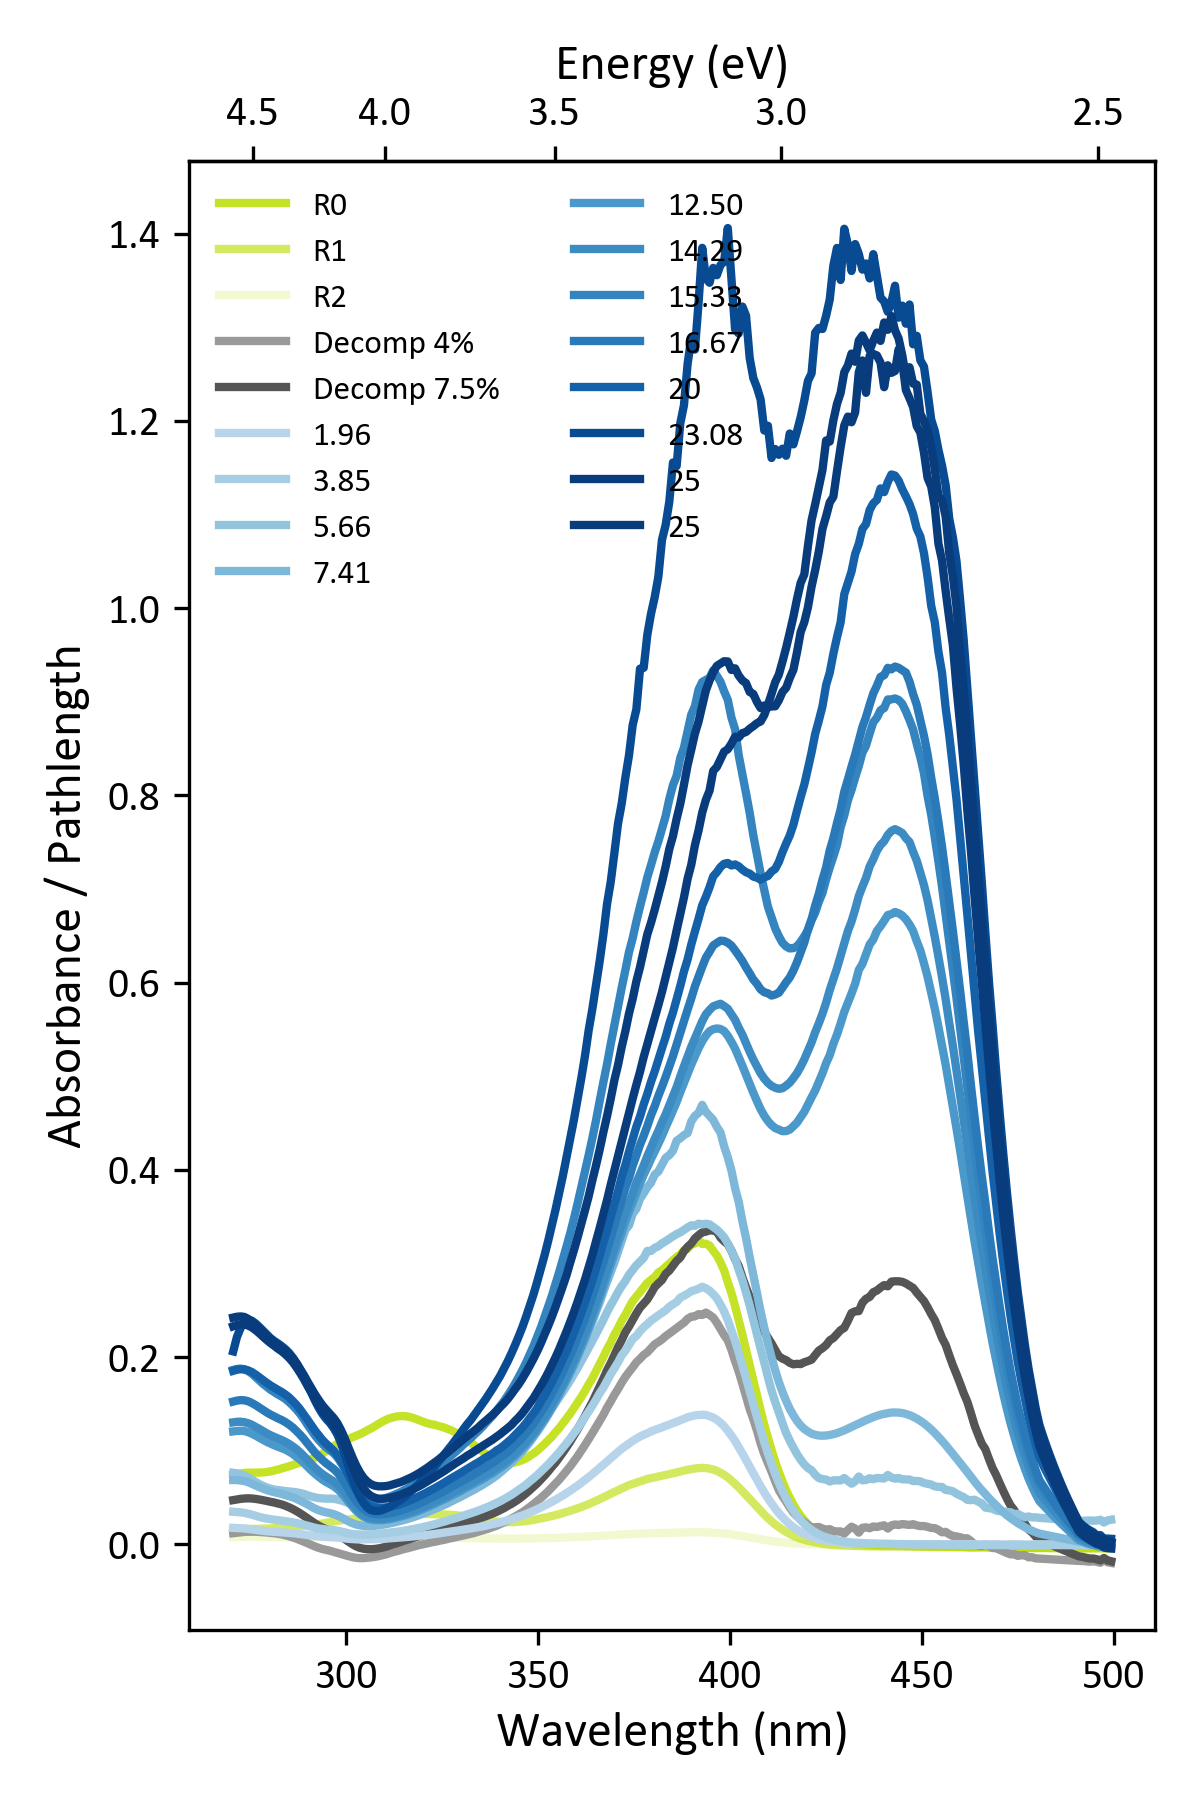

In [93]:
# ============================================================
# 4. CONFIGURACIÓN, GRADIENTE Y PLOT
# ============================================================
# Formato: (Variable, "Concentración", Pathlength_libre, "gradient", Linestyle)
spectra_config = [
    
    (S20260528_F006_R0_d20, "R0", 5.0, "#BCDD02DA", "-"),
    (S20260528_F006_R1_d20, "R1", 5.0, "#BCDD02A0", "-"),
    (S20260528_F006_R2_d20, "R2", 5.0, "#BCDD0230", "-"),
    
    (S20261007_phDADQ_DecompSublim_DMF_20ul_500ul_QS_5mm_200nm_1100nm, "Decomp 4% ", 5.0, "#999999", "-"),
    (S20261007_phDADQ_DecompSublim_DMF_40ul_500ul_QS_5mm_200nm_1100nm, "Decomp 7.5% ", 5.0, "#555555", "-"),
        
    #(S20260618_phDADQ_DMF_10, " %",  5.0, "gradient:Blues", "-"),
    #(S20260618_phDADQ_DMF_20, " %",  5.0, "gradient:Blues", "-"),
    #(S20260618_phDADQ_DMF_50, "%",  5.0, "gradient:Blues", "-"),
    #(S20260618_phDADQ_DMF_70, " %",  5.0, "gradient:Blues", "-"),
    #(S20260618_phDADQ_DMF_100, " %", 5.0, "gradient:Blues", "-"),
    #(S20260618_phDADQ_DMF_200, " %", 5.0, "gradient:Blues", "-"),

    (S20261007_phDADQ_100pcSat_DMF_10ul_500ul_QS_5mm_200nm_1100nm,  "1.96",   5.0, "gradient:Blues", "-"),
    (S20261007_phDADQ_100pcSat_DMF_20ul_500ul_QS_5mm_200nm_1100nm,  "3.85",   5.0 , "gradient:Blues", "-"),
    (S20261007_phDADQ_100pcSat_DMF_30ul_500ul_QS_5mm_200nm_1100nm,  "5.66",   5.0, "gradient:Blues", "-"),
    (S20261007_phDADQ_100pcSat_DMF_40ul_500ul_QS_5mm_200nm_1100nm,  "7.41",   5.0, "gradient:Blues", "-"),
    #(S20261007_phDADQ_100pcSat_DMF_50ul_500ul_QS_5mm_200nm_1100nm,  "9.09",   5.0, "gradient:Blues", "-"),
    #(S20261007_phDADQ_100pcSat_DMF_60ul_500ul_QS_5mm_200nm_1100nm,  "10.71",  5.0, "gradient:Blues", "-"),
    #(S20261007_phDADQ_100pcSat_DMF_70ul_500ul_QS_5mm_200nm_1100nm,  "12.28",  5.0, "gradient:Blues", "-"),

    (S20261007_phDADQ_100pcSat_DMF_100ul_700ul_QS_2mm_200nm_1100nm, "12.50",  2.0, "gradient:Blues", "-"),
    (S20261007_phDADQ_100pcSat_DMF_100ul_600ul_QS_2mm_200nm_1100nm, "14.29",  2.0, "gradient:Blues", "-"),
    (S20261007_phDADQ_23pcSat_DMF_400ul_200ul_QS_2mm_200nm_1100nm,  "15.33",  2.0, "gradient:Blues", "-"),
    
    ##(S20261007_phDADQ_100pcSat_DMF_100ul_500ul_QS_5mm_200nm_1100nm, "16.67",  5.0, "gradient:Blues", "-"),
    
    (S20261007_phDADQ_100pcSat_DMF_100ul_500ul_QS_2mm_200nm_1100nm, "16.67",  2.0, "gradient:Blues", "-"),
    (S20261007_phDADQ_100pcSat_DMF_100ul_400ul_QS_2mm_200nm_1100nm, "20",     2.0, "gradient:Blues", "-"),
    
    ##(S20261007_phDADQ_100pcSat_DMF_150ul_500ul_QS_5mm_200nm_1100nm, "23.08",  5.0, "gradient:Blues", "-"),
    
    (S20261007_phDADQ_100pcSat_DMF_150ul_500ul_QS_2mm_200nm_1100nm, "23.08",  2.0, "gradient:Blues", "-"),
    (S20261007_phDADQ_100pcSat_DMF_200ul_600ul_QS_2mm_200nm_1100nm, "25",     2.0, "gradient:Blues", "-"),
    (S20261007_phDADQ_100pcSat_DMF_100ul_300ul_QS_2mm_200nm_1100nm, "25",     2.0, "gradient:Blues", "-"),
    ##(S20261007_phDADQ_100pcSat_DMF_200ul_500ul_QS_2mm_200nm_1100nm, "28.57",  2.0, "gradient:Blues", "-"),
    ###(S20261007_phDADQ_100pcSat_DMF_200ul_400ul_QS_2mm_200nm_1100nm, "33.33",  2.0, "gradient:Blues", "-"),
    ###(S20261007_phDADQ_100pcSat_DMF_200ul_300ul_QS_2mm_200nm_1100nm, "40",     2.0, "gradient:Blues", "-"),
    ###(S20261007_phDADQ_100pcSat_DMF_200ul_200ul_QS_2mm_200nm_1100nm, "50",     2.0, "gradient:Blues", "-"),
    ###(S20261007_phDADQ_100pcSat_DMF_200ul_100ul_QS_2mm_200nm_1100nm, "66.67",  2.0, "gradient:Blues", "-"),
    ###(S20261007_phDADQ_100pcSat_DMF_200ul_0ul_QS_2mm_200nm_1100nm,   "100",    2.0, "gradient:Blues", "-"),


]

# --- LÓGICA PARA CREAR EL GRADIENTE DE COLOR ---
colormap_values = {}
for item in spectra_config:
    col_str = str(item[3])
    if col_str.startswith("gradient"):
        # Extraer el nombre del colormap (o "Blues" por defecto)
        cmap_name = col_str.split(":")[1] if ":" in col_str else "Blues"
        try:
            val = float(item[1])
            if cmap_name not in colormap_values:
                colormap_values[cmap_name] = []
            colormap_values[cmap_name].append(val)
        except ValueError:
            pass

# 2. Crear una normalización (min/max) dinámica para cada colormap detectado
colormap_norms = {}
for cmap_name, values in colormap_values.items():
    if values:
        colormap_norms[cmap_name] = mcolors.Normalize(vmin=min(values), vmax=max(values))

# --- CREACIÓN DE LA SELECCIÓN ---
SelectionUVvis = []
for var, name, path_val, col, ls in spectra_config:
    s = var.copy()  
    s.N = name
    s.pathlength = path_val
    
    col_str = str(col)
    if col_str.startswith("gradient"):
        cmap_name = col_str.split(":")[1] if ":" in col_str else "Blues"
        try:
            val = float(name)
            # Aplicar el color usando el norm correspondiente a este colormap
            if cmap_name in colormap_norms:
                norm = colormap_norms[cmap_name]
                cmap_obj = plt.get_cmap(cmap_name)
                # Ajustamos el rango (0.3 - 0.95) para evitar el blanco invisible
                color_mapped = cmap_obj(0.3 + 0.65 * norm(val)) 
                s.color = mcolors.to_hex(color_mapped)
            else:
                s.color = "#000000" # Seguro por si acaso
        except ValueError:
            s.color = "#808080" # Color gris si el nombre no se puede pasar a float
    else:
        s.color = col
        
    s.linestyle = ls
    SelectionUVvis.append(s)

# --- PIPELINE DE CORRECCIÓN ---
# 1. Aplicamos la división por pathlength (A / mm)
SelectionUVvis = ApplyPathlengthCorrection(SelectionUVvis)

# 2. Recortamos al rango deseado
SelectionUVvis = TrimSpectra(SelectionUVvis, xmin=270, xmax=500)

poster_style = {
    "figsize": (4, 6),
    "dpi": 300,
    "font_size": 10,
    "title_size": 12,
    "label_size": 12,
    "legend_size": 8,
    "line_width": 2,
    "font_family": "Calibri",
    "grid": False,               
}
PlotSpectra(
    spectra_list=SelectionUVvis,
    mode="WE",
    offset_step=0.0,
    #ymax=3.2,
    ylabel="Absorbance / Pathlength",
    style=poster_style,
    legend_ncol=2 # Ajustado a 2 columnas para que quepan todos los labels
)

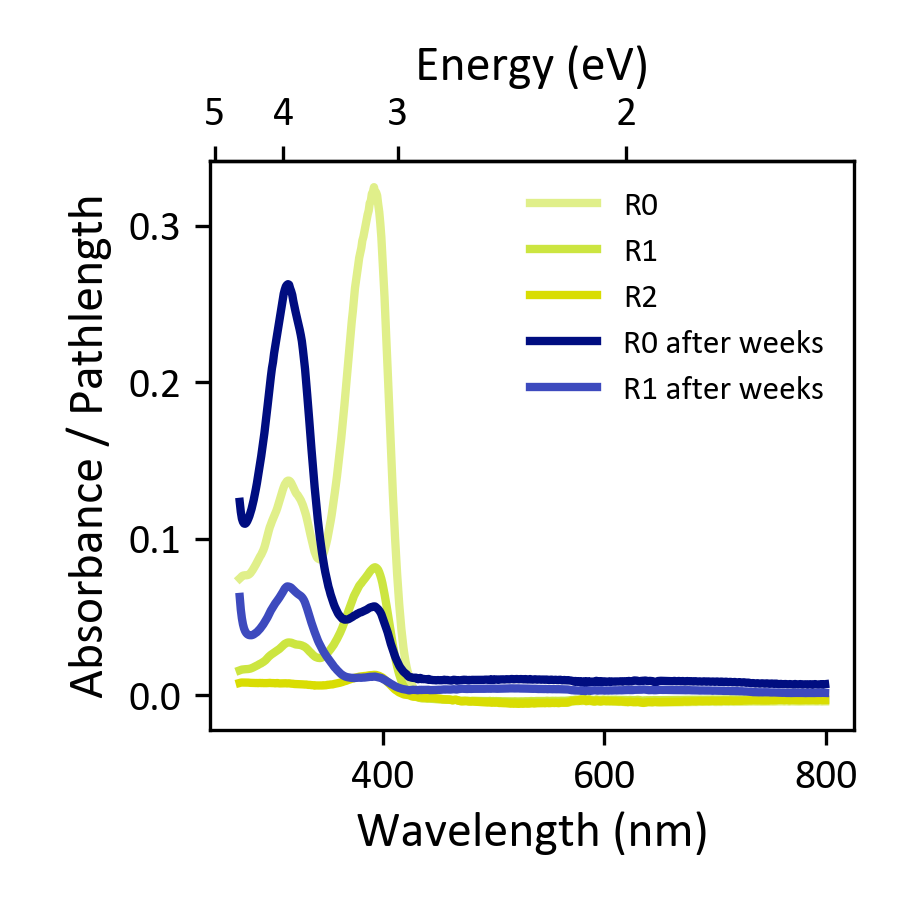

In [98]:
# ============================================================
# 4. CONFIGURACIÓN, GRADIENTE Y PLOT
# ============================================================
# Formato: (Variable, "Concentración", Pathlength_libre, "gradient", Linestyle)
spectra_config = [
    
    #(S20260618_phDADQ_DMF_10, "0.57%",  5.0, "gradient:Blues", "-"),
    #(S20260618_phDADQ_DMF_20, "1.14%",  5.0, "gradient:Blues", "-"),
    #(S20260618_phDADQ_DMF_50, "2.86%",  5.0, "gradient:Blues", "-"),
    #(S20260618_phDADQ_DMF_70, "4.00%",  5.0, "gradient:Blues", "-"),
    #(S20260618_phDADQ_DMF_100, "5.71%", 5.0, "gradient:Blues", "-"),
    #(S20260618_phDADQ_DMF_200, "11.43%", 5.0, "gradient:Blues", "-"),

    #(S20261007_phDADQ_100pcSat_DMF_30ul_500ul_QS_5mm_200nm_1100nm,  "5.66",   5.0, "red", "-"),
    #(S20261007_phDADQ_100pcSat_DMF_100ul_700ul_QS_2mm_200nm_1100nm, "12.50",  2.0, "red", "-"),
    (S20260528_F006_R0_d20, "R0", 5.0, "#BCDD0276", "-"),
    (S20260528_F006_R1_d20, "R1", 5.0, "#BCDD02C1", "-"),
    (S20260528_F006_R2_d20, "R2", 5.0, "#D9DD02FF", "-"),

    #(S0_noBL, "0",  5.0, "green", "-"),
    #(S1_noBL, "1",  5.0, "#00800077", "-"),
    #(S2_noBL, "2",  5.0, "#00800017", "-"),
    #(Sunnumbered_noBL, "nobl",  5.0, "green", "-"),
    (S0_unnumberedBL, "R0 after weeks", 5.0, "#000d80", "-"),
    (S1_unnumberedBL, "R1 after weeks", 5.0, "#3d4abe", "-"),
    #(S2_unnumberedBL, "02", 5.0, "#656779", "-"),


]

# --- LÓGICA PARA CREAR EL GRADIENTE DE COLOR ---
colormap_values = {}
for item in spectra_config:
    col_str = str(item[3])
    if col_str.startswith("gradient"):
        # Extraer el nombre del colormap (o "Blues" por defecto)
        cmap_name = col_str.split(":")[1] if ":" in col_str else "Blues"
        try:
            val = float(item[1])
            if cmap_name not in colormap_values:
                colormap_values[cmap_name] = []
            colormap_values[cmap_name].append(val)
        except ValueError:
            pass

# 2. Crear una normalización (min/max) dinámica para cada colormap detectado
colormap_norms = {}
for cmap_name, values in colormap_values.items():
    if values:
        colormap_norms[cmap_name] = mcolors.Normalize(vmin=min(values), vmax=max(values))

# --- CREACIÓN DE LA SELECCIÓN ---
SelectionUVvis = []
for var, name, path_val, col, ls in spectra_config:
    s = var.copy()  
    s.N = name
    s.pathlength = path_val
    
    col_str = str(col)
    if col_str.startswith("gradient"):
        cmap_name = col_str.split(":")[1] if ":" in col_str else "Blues"
        try:
            val = float(name)
            # Aplicar el color usando el norm correspondiente a este colormap
            if cmap_name in colormap_norms:
                norm = colormap_norms[cmap_name]
                cmap_obj = plt.get_cmap(cmap_name)
                # Ajustamos el rango (0.3 - 0.95) para evitar el blanco invisible
                color_mapped = cmap_obj(0.3 + 0.65 * norm(val)) 
                s.color = mcolors.to_hex(color_mapped)
            else:
                s.color = "#000000" # Seguro por si acaso
        except ValueError:
            s.color = "#808080" # Color gris si el nombre no se puede pasar a float
    else:
        s.color = col
        
    s.linestyle = ls
    SelectionUVvis.append(s)

# --- PIPELINE DE CORRECCIÓN ---
# 1. Aplicamos la división por pathlength (A / mm)
SelectionUVvis = ApplyPathlengthCorrection(SelectionUVvis)

# 2. Recortamos al rango deseado
SelectionUVvis = TrimSpectra(SelectionUVvis, xmin=270, xmax=800)

poster_style = {
    "figsize": (3, 3),
    "dpi": 300,
    "font_size": 10,
    "title_size": 12,
    "label_size": 12,
    "legend_size": 8,
    "line_width": 2,
    "font_family": "Calibri",
    "grid": False,               
}
PlotSpectra(
    spectra_list=SelectionUVvis,
    mode="WE",
    offset_step=0.0,
    #ymax=3.2,
    ylabel="Absorbance / Pathlength",
    style=poster_style,
    legend_ncol=1 # Ajustado a 2 columnas para que quepan todos los labels
)

In [ ]:
# ============================================================
# 4. SELECTION, PIPELINE & PLOTTING
# ============================================================

# 1. Define tu configuración maestra aquí (¡Cualquier cambio aquí se aplicará al instante!)
spectra_config = [
    # (Variable, Nombre, wcorr, Color, Linestyle)
    (S20260817_F007WA_1BrC18_P2_DGUdial, "1BrC18@SWCNTs", 0.2, "#D55E00", "-"),
    (S20260817_F005LP_6FBz_P2_DGUdial,   "6FBz@SWCNTs",   1.5, "#009E73", "-"),
    (S20260817_P2_DGUdial,               "H2O@SWCNTs",    0.0, "#0072B2", "-"),
    (S20260817_F006WA_phDADQ_P2_DGUdial, "phDADQ@SWCNTs",  0.3, "#000000", "-"),

]

# 2. Construcción fresca de la lista Selection
Selection = []
for var, name, factor, col, ls in spectra_config:
    s = var.copy()
    s.N = name
    s.wcorr = factor
    s.color = col
    s.linestyle = ls
    Selection.append(s)

# --- PIPELINE DE CORRECCIÓN ---
# (Nota: Asegúrate de que tus funciones de procesamiento usen s.copy() 
# propagando s.color y s.linestyle. Si no lo hacen, los pierden en el camino).
Selection = SubtractBaseline(Selection, baseline)
Selection = ApplyCalibrationCorrection(Selection, water_calibration) 
Selection = NormalizeSpectra(Selection, xmin=1200, xmax=1350, mode="V")
Selection = TrimSpectra(Selection, xmin=228, xmax=1850)
Selection = BackgroundCorrection(Selection, a=1400, b=0)


if 1==1:
    Substracted = Selection[3].copy()
    Substracted.N = "Substracted spec. (phDADQ@SWCNT-1BrC18@SWCNTs)"  # Dale un nombre limpio para la leyenda
    Substracted.color = "#CC79A7"               # Un color distintivo para la resta

    # Restamos los arrays Y
    additionalOffset = 0
    Substracted.Y = Selection[3].Y - Selection[2].Y - additionalOffset
    Substracted = TrimSpectra(Substracted, xmin=290, xmax=800)

    # Lo agregamos a la lista que vamos a graficar
    Selection.append(Substracted)

# --- GRAFICAR ---
    
poster_style = {
    "figsize": (6,4),
    "dpi": 300,
    "font_size": 10,
    "title_size": 12,
    "label_size": 12,
    "legend_size": 8,
    "line_width": 2,
    "font_family": "Calibri",
    "grid": False,               
    "colors": ["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#56B4E9", "#D55E00", "#F0E442"], 
    "linestyles": ["-", "--", "-.", ":"]
}


PlotSpectra(
    spectra_list=Selection,
    mode="WE",
    offset_step=-0.6,
    ylabel="Absorbance",
    hide_yticks=True,
    xmax=1850,
    xmin=230,
    style=poster_style,
    )



#picos = [418, 461.50, 486, 514.0, 545.5, 582, 935, 979.5, 1005.5, 1063, 1136.5]
picos = [935,979,1005,1063,1136,1583,1660,1727,1768]

for xi in picos: 
    # Usamos ax1.axvline en lugar de plt.axvline
    plt.axvline(x=xi, linewidth=0.5, linestyle='--', color='black', alpha=0.7, zorder=0)

#Peaks = FindExtrema(Selection[0], mode="maxima", distance=10, prominence=0.1, xmin=900, xmax=1840)

